### 1. Φόρτωση Καθαρών Περασμάτων & Προετοιμασία Μεταβλητών

In [7]:
# Φόρτωση του clean_results.csv, φιλτράρισμα των καθαρών περασμάτων (Is_Clean_Pass == True)
# και δημιουργία ετικετών για τη Διαδρομή (Αριστερή / Δεξιά) και τη Φάση Αγώνα (Προκριματικά vs Eliminations).

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

PROCESSED_DIR = os.path.join("..", "data", "processed")
FIGURES_DIR = os.path.join("..", "outputs", "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)

results = pd.read_csv(os.path.join(PROCESSED_DIR, "clean_results.csv"))
# Εξαίρεση των Φορτηγών από το dataset (έχουν ελάχιστα περάσματα) --> γιαυτό το Σύνολο Καθαρών Περασμάτων θα είναι λίγο λιγότερα από αυτά που βγάζει το notebook_01!
results = results[results['ΤύποςΟχήματος'] != 'Φορτηγό'].copy()

clean = results[results['Is_Clean_Pass'] == True].copy()

# Αντιστοίχιση ονομάτων Διαδρομής (1 = Αριστερή, 2 = Δεξιά) και Φάσης Αγώνα
clean['Διαδρομή_Όνομα'] = clean['Διαδρομή'].map({1: 'Αριστερή (Lane 1)', 2: 'Δεξιά (Lane 2)'})
# Αν η ΠεριγραφήΚατάταξης == 'Με Συνολικό Χρόνο' τότε είμαστε σε κόντρες (μετράει και το reaction time), αλλιώς είμαστε σε προκριματικά ή ελεύθερα δοκιμαστικά (ΠεριγραφήΚατάταξης == 'Με χρόνο τερματισμού' ή 'Με διαφορά δηλωτού χρόνου')
clean['Φάση_Αγώνα'] = np.where(
    clean['ΠεριγραφήΚατάταξης'] == 'Με Συνολικό Χρόνο',
    'Eliminations (Κόντρες)',
    'Προκριματικά / Δοκιμαστικά' # Δοκιμαστικά = ΕΛΕΥΘΕΡΑ ΔΟΚΙΜΑΣΤΙΚΑ
)

clean_400 = clean[(clean['Απόσταση_Κατηγορίας_m'] == 400) & (clean['Χρόνος200_sec'] > 3.5)].copy() # βγάζω τα περάσματα που δεν έχουν χρόνο στα 200 γιατί μετά υπολογίζω BackHalf 200-400m
clean_200 = clean[clean['Απόσταση_Κατηγορίας_m'] == 200].copy()

print(f"Σύνολο Καθαρών Περασμάτων: {len(clean)}")
print(f" -> Καθαρά Περάσματα 400m (με πλήρη ενδιάμεσα splits): {len(clean_400)}")
print(f" -> Καθαρά Περάσματα 200m (<200>): {len(clean_200)}")

Σύνολο Καθαρών Περασμάτων: 11421
 -> Καθαρά Περάσματα 400m (με πλήρη ενδιάμεσα splits): 9575
 -> Καθαρά Περάσματα 200m (<200>): 1840


### 2. Περιγραφικά Στατιστικά Ενδιάμεσων Χρόνων (Splits 18m, 200m, Back-Half, 400m)

In [8]:
# Υπολογισμός βασικών περιγραφικών στατιστικών (Count, Mean, Median, Std, Min, Max)
# για όλα τα τμήματα της πίστας 400m (18m/60ft, 200m, Back-Half 200-400m, 400m ET) ανά Τύπο Οχήματος.

def calc_stats(series):
    return pd.Series({
        'Count (Πλήθος)': series.count(),
        'Mean (Μέσος Όρος)': series.mean(),
        'Median (Διάμεσος)': series.median(),
        'Std (Τυπ. Απόκλιση)': series.std(),
        'Min (Ελάχιστο)': series.min(),
        'Max (Μέγιστο)': series.max()
    }).round(3)

cars_400 = clean_400[clean_400['ΤύποςΟχήματος'] == 'Αυτοκίνητο']
bikes_400 = clean_400[clean_400['ΤύποςΟχήματος'] == 'Μηχανή']

splits_stats = pd.DataFrame({
    'Αυτοκίνητο 18m (s)': calc_stats(cars_400['Χρόνος18_sec']),
    'Μηχανή 18m (s)': calc_stats(bikes_400['Χρόνος18_sec']),
    'Αυτοκίνητο 200m (s)': calc_stats(cars_400['Χρόνος200_sec']),
    'Μηχανή 200m (s)': calc_stats(bikes_400['Χρόνος200_sec']),
    'Αυτοκίνητο BackHalf 200-400m (s)': calc_stats(cars_400['BackHalf_200_400_sec']),
    'Μηχανή BackHalf 200-400m (s)': calc_stats(bikes_400['BackHalf_200_400_sec']),
    'Αυτοκίνητο 400m ET (s)': calc_stats(cars_400['Χρόνος400_sec']),
    'Μηχανή 400m ET (s)': calc_stats(bikes_400['Χρόνος400_sec'])
})

display(splits_stats)

,Αυτοκίνητο 18m (s),Μηχανή 18m (s),Αυτοκίνητο 200m (s),Μηχανή 200m (s),Αυτοκίνητο BackHalf 200-400m (s),Μηχανή BackHalf 200-400m (s),Αυτοκίνητο 400m ET (s),Μηχανή 400m ET (s)
Count (Πλήθος),3667.000,5908.000,3667.000,5908.000,3667.000,5908.000,3667.000,5908.000
Mean (Μέσος Όρος),1.876,1.617,7.933,6.467,4.364,3.646,12.298,10.113
Median (Διάμεσος),1.795,1.596,7.767,6.251,4.167,3.312,12.008,9.570
Std (Τυπ. Απόκλιση),0.311,0.185,1.078,0.763,0.852,0.827,1.738,1.510
Min (Ελάχιστο),1.276,0.886,5.249,4.506,2.755,2.876,8.004,8.133
Max (Μέγιστο),3.462,3.326,14.197,12.536,8.948,10.707,19.902,19.969


### 3. Συσχέτιση & Παλινδρόμηση 18m (60ft) vs 400m ET
- #### Η κλίση δεν είναι αιτιότητα. Οι γρήγορες εκκινήσεις συνήθως συνοδεύουν γρηγορότερα οχήματα, οπότε μέρος του "κέρδους" οφείλεται στο ότι ένα καλύτερο όχημα είναι γρήγορο παντού. Το 0.1 s στα 18m δεν σημαίνει απαραίτητα ότι αν βελτιώσεις μόνο την εκκίνηση θα κερδίσεις τόσο.
- #### Το Pearson r (200m vs 400m) είναι σχεδόν εγγυημένα υψηλό, γιατί το 200m περιέχεται στο 400m, άρα δεν είναι ιδιαίτερα πληροφοριακό.

In [9]:
# Υπολογισμός συσχέτισης (Pearson r & Spearman r) και γραμμικής παλινδρόμησης (scipy.stats.linregress)
# μεταξύ του χρόνου εκκίνησης 18m (60ft) και του τελικού χρόνου 400m ET.
# Ποσοτικοποιεί πόσο χρόνο κερδίζει ένα όχημα στα 400m για κάθε 0.1s βελτίωσης στα πρώτα 18 μέτρα.

reg_rows = []
for vtype, sub in [('Αυτοκίνητο', cars_400), ('Μηχανή', bikes_400)]:
    slope_18, intercept_18, r_18, p_18, _ = stats.linregress(sub['Χρόνος18_sec'], sub['Χρόνος400_sec'])
    r_sp_18, _ = stats.spearmanr(sub['Χρόνος18_sec'], sub['Χρόνος400_sec'])
    slope_200, _, r_200, _, _ = stats.linregress(sub['Χρόνος200_sec'], sub['Χρόνος400_sec'])
    
    reg_rows.append({
        'Τύπος Οχήματος': vtype,
        'Πλήθος (n)': len(sub),
        'Pearson r (18m vs 400m)': round(r_18, 3),
        'Spearman r (18m vs 400m)': round(r_sp_18, 3),

        # Η κλίση (slope_18) δείχνει πόσα δευτερόλεπτα αλλάζει ο χρόνος 400m για κάθε 1 s αλλαγή στα 18m.
        # Επειδή το 1 s στα 18m είναι μη ρεαλιστικά μεγάλη διαφορά, πολλαπλασιάζουμε επί 0.1 ώστε το αποτέλεσμα
        # να αναφέρεται σε μια ρεαλιστική βελτίωση 0.1 s (η σχέση είναι γραμμική, άρα κέρδος = κλίση × Δx).
        'Κέρδος 400m ανά -0.1s στα 18m (s)': round(slope_18 * 0.1, 3),
        
        'Pearson r (200m vs 400m)': round(r_200, 3),
        'p-value (18m vs 400m)': f"{p_18:.2e}"
    })

reg_df = pd.DataFrame(reg_rows)
display(reg_df)

,Τύπος Οχήματος,Πλήθος (n),Pearson r (18m vs 400m),Spearman r (18m vs 400m),Κέρδος 400m ανά -0.1s στα 18m (s),Pearson r (200m vs 400m),p-value (18m vs 400m)
0,Αυτοκίνητο,3667,0.624,0.608,0.349,0.923,0.00e+00
1,Μηχανή,5908,0.453,0.446,0.370,0.946,3.46e-297


### **Τι δείχνει ο έλεγχος συσχέτισης και γραμμικής παλινδρόμησης (18m & 200m vs 400m):**
- ##### **Αυτοκίνητα (n = 3.667):** Ο χρόνος στα πρώτα 18m (60ft) σχετίζεται ισχυρά και στατιστικά σημαντικά με τον τελικό χρόνο στα 400m (Pearson r = 0.624, Spearman r = 0.608, p < 0.0001). Ο συντελεστής προσδιορισμού (R² = 0.390) δείχνει ότι περίπου το 39% της διακύμανσης του χρόνου 400m συνδέεται με την επίδοση στα πρώτα 18 μέτρα. Από την κλίση της ευθείας παλινδρόμησης προκύπτει ότι **κάθε 0.1 s ταχύτερη εκκίνηση στα 18m συνδέεται κατά μέσο όρο με 0.349 s ταχύτερο τερματισμό στα 400m**.
- ##### **Μηχανές (n = 5.908):** Η συσχέτιση του χρόνου 18m με τον τελικό χρόνο 400m είναι μέτρια και στατιστικά σημαντική (Pearson r = 0.453, Spearman r = 0.446, p < 0.0001, R² = 0.205). **Κάθε 0.1 s ταχύτερη εκκίνηση στα 18m συνδέεται κατά μέσο όρο με 0.370 s ταχύτερο τερματισμό στα 400m**, με την εκκίνηση από μόνη της να εξηγεί μικρότερο ποσοστό της τελικής διακύμανσης στις μηχανές (~20.5%) σε σχέση με τα αυτοκίνητα (δηλ. Η εκκίνηση φαίνεται να προβλέπει λιγότερο τον τελικό χρόνο στις μηχανές).
- ##### **Σημείο των 200m:** Η συσχέτιση του ενδιάμεσου χρόνου 200m με τον τελικό χρόνο 400m είναι εξαιρετικά υψηλή τόσο στα αυτοκίνητα (r = 0.923, R² = 0.852) όσο και στις μηχανές (r = 0.946, R² = 0.895), επιβεβαιώνοντας ότι στα μισά της διαδρομής η τελική επίδοση έχει ήδη κριθεί σε ποσοστό 85%-90% (αναμενόμενο).
- ##### **Προσοχή στην ερμηνεία:** Πρόκειται για στατιστική συσχέτιση μεταξύ όλων των κατηγοριών και όχι για απομονωμένη αιτιότητα. Ένα πιο ισχυρό και καλοστημένο όχημα που ξεκινά γρήγορα στα 18m συνεχίζει να επιταχύνει ταχύτερα και στην υπόλοιπη διαδρομή, επομένως μέρος του κέρδους οφείλεται στη συνολική δυναμικότητα του οχήματος και στο ότι οι κατηγορίες διαφέρουν σε ισχύ.

### 4. Ανάλυση Χρόνων Αντίδρασης (Net_RT_sec) & Red Lights (Προκριματικά vs Eliminations)
- #### Εξαιρέθηκαν περάσματα με καθαρό χρόνο αντίδρασης `Net RT > 1.5s`, καθώς αντιπροσωπεύουν μηχανική καθυστέρηση turbo / εμπλοκής DSG (spool-up / launch control) ή ηθελημένη αναμονή στα προκριματικά / ελεύθερα δοκιμαστικά, και όχι ανθρώπινο χρόνο αντίδρασης.

In [10]:
# Ανάλυση του Καθαρού Χρόνου Αντίδρασης (Net_RT_sec = ΧρόνοςΑντίδρασης_sec - 0.400)
# και του ποσοστού Άκυρων Εκκινήσεων (Red Lights / Εγκυρη == -1) ανάμεσα στα Προκριματικά
# (Προκριματικά / Δοκιμαστικά) και τις Κόντρες (Eliminations).

# 1. Στατιστικά Καθαρού Χρόνου Αντίδρασης (έγκυρες αντιδράσεις 0.000s έως 1.500s)
    # ΔΕΝ ΠΡΕΠΕΙ να συμπεριλάβω και τα DSG/Turbo αυτοκίνητα που χρειάζονται παραπάνω δευτερόλεπτα πριν πάρουν εκκίνηση για να χτίσουν πίεση, γιατί ΧΑΝΕΤΑΙ ΤΟ ΝΟΗΜΑ της ανάλυσης!
rt_clean = clean[clean['Net_RT_sec'].between(0.0, 1.5)].copy()

rt_summary = (
    rt_clean.groupby(['Φάση_Αγώνα', 'ΤύποςΟχήματος'])['Net_RT_sec']
    .agg(Count='count', Mean='mean', Median='median', Std='std', Min='min', Max='max')
    .round(3)
    .reset_index()
)
print("1. Καθαρός Χρόνος Αντίδρασης (Net_RT_sec) ανά Φάση Αγώνα & Τύπο Οχήματος:")
display(rt_summary)

# 2. Συχνότητα Άκυρων Εκκινήσεων (Red Lights: Εγκυρη == -1) ανά Φάση Αγώνα
champ_runs = results[(results['ΠΙΣΤΑ'] != 'ΔΟΚΙΜΕΣ') & (results['ααΣυμμετοχής'] > 0)].copy()
champ_runs['Φάση_Αγώνα'] = np.where(
    champ_runs['ΠεριγραφήΚατάταξης'] == 'Με Συνολικό Χρόνο',
    'Eliminations (Κόντρες)',
    'Προκριματικά / Δοκιμαστικά'
)

rl_summary = champ_runs.groupby('Φάση_Αγώνα').agg(
    Σύνολο_Περασμάτων=('ααΕπίδοσης', 'count'),
    Red_Lights=('Εγκυρη', lambda s: (s == -1).sum())
).reset_index()
rl_summary['Ποσοστό Red Light (%)'] = (
    rl_summary['Red_Lights'] / rl_summary['Σύνολο_Περασμάτων'] * 100
).round(2)

print("\n2. Ποσοστό Άκυρων Εκκινήσεων (Red Lights) ανά Φάση Αγώνα:")
display(rl_summary)

1. Καθαρός Χρόνος Αντίδρασης (Net_RT_sec) ανά Φάση Αγώνα & Τύπο Οχήματος:


,Φάση_Αγώνα,ΤύποςΟχήματος,Count,Mean,Median,Std,Min,Max
0,Eliminations (Κόντρες),Αυτοκίνητο,664,0.524,0.464,0.337,0.009,1.498
1,Eliminations (Κόντρες),Μηχανή,1289,0.223,0.149,0.234,0.000,1.484
2,Προκριματικά / Δοκιμαστικά,Αυτοκίνητο,1552,0.671,0.584,0.360,0.008,1.491
3,Προκριματικά / Δοκιμαστικά,Μηχανή,4936,0.467,0.357,0.365,0.000,1.498



2. Ποσοστό Άκυρων Εκκινήσεων (Red Lights) ανά Φάση Αγώνα:


,Φάση_Αγώνα,Σύνολο_Περασμάτων,Red_Lights,Ποσοστό Red Light (%)
0,Eliminations (Κόντρες),3361,185,5.50
1,Προκριματικά / Δοκιμαστικά,10519,123,1.17


### **Τι δείχνει η ανάλυση των Χρόνων Αντίδρασης (Net_RT_sec) & Red Lights (Προκριματικά vs Eliminations):**
- ##### **Στις Μηχανές:** Ο διάμεσος καθαρός χρόνος αντίδρασης βελτιώνεται εντυπωσιακά (κατά 58%), πέφτοντας από τα **0.357 s** (μέσος όρος 0.467 s) στα Προκριματικά / Δοκιμαστικά στα **0.149 s** (μέσος όρος 0.223 s) στις Κόντρες (Eliminations).
- ##### **Στα Αυτοκίνητα:** Ο διάμεσος καθαρός χρόνος αντίδρασης μειώνεται από τα **0.584 s** (μέσος όρος 0.671 s) στα Προκριματικά / Δοκιμαστικά στα **0.464 s** (μέσος όρος 0.524 s) στις Κόντρες.
- ##### **Άκυρες Εκκινήσεις - Red Lights (Εγκυρη == -1):** Επειδή στα Προκριματικά / Δοκιμαστικά μετράει μόνο ο καθαρός χρόνος διαδρομής (ET) ενώ στις Κόντρες (Eliminations) η νίκη κρίνεται στον συνολικό χρόνο (Χρόνος Αντίδρασης + ET), οι οδηγοί πιέζουν το φανάρι στο όριο. Ως αποτέλεσμα, το ποσοστό των Red Lights σχεδόν πενταπλασιάζεται (4.7x), ανεβαίνοντας από **1.17%** στα Προκριματικά / Δοκιμαστικά (123 σε 10.519 περάσματα) σε **5.50%** στις Κόντρες (185 σε 3.361 περάσματα)!

### 5. Έλεγχος Ισοτιμίας Διαδρομών (Lane Bias Audit: Αριστερή vs Δεξιά Διαδρομή)

In [ ]:
# Στατιστικός έλεγχος ισοτιμίας Αριστερής (Lane 1) vs Δεξιάς (Lane 2) Διαδρομής:
# 1. Έλεγχος Mann-Whitney U στους χρόνους εκκίνησης (18m) και τερματισμού (400m).
# 2. Υπολογισμός ποσοστού νικών (Win Rate) και έλεγχος Chi-Square (Goodness-of-Fit) στις πραγματικές
#    Head-to-Head κόντρες των Eliminations (εξαιρώντας τα Bye / Δεν προσήλθε / ΝΑΑγώνα).

lane_rows = []
for vtype, sub in [('Αυτοκίνητο', cars_400), ('Μηχανή', bikes_400)]:
    l1 = sub[sub['Διαδρομή'] == 1]
    l2 = sub[sub['Διαδρομή'] == 2]
    _, p_18 = stats.mannwhitneyu(l1['Χρόνος18_sec'], l2['Χρόνος18_sec'])
    _, p_400 = stats.mannwhitneyu(l1['Χρόνος400_sec'], l2['Χρόνος400_sec'])

    # κώδικας για το 3ο συμπέρασμα "Έλεγχος για τους ίδιους οδηγούς"
    # # διάμεσος χρόνος 400m ανά οδηγό, αγώνα και λωρίδα (μόνο όσοι έτρεξαν και στις δύο)
    # pair = (
    # sub.groupby(['Race_UID', 'Ονοματεπώνυμο', 'Διαδρομή'])['Χρόνος400_sec']
    # .median().unstack('Διαδρομή').dropna(subset=[1, 2])
    # )
    # stat, p = stats.wilcoxon(pair[1], pair[2])
    # print(len(pair), (pair[1] - pair[2]).median(), p)
    
    lane_rows.append({
        'Τύπος Οχήματος': vtype,
        'Πλήθος (Αριστερή / Δεξιά)': f"{len(l1)} / {len(l2)}",
        'Διάμεσος 18m Αριστερή (s)': round(l1['Χρόνος18_sec'].median(), 3),
        'Διάμεσος 18m Δεξιά (s)': round(l2['Χρόνος18_sec'].median(), 3),
        'p-value 18m': round(p_18, 4),
        'Διάμεσος 400m Αριστερή (s)': round(l1['Χρόνος400_sec'].median(), 3),
        'Διάμεσος 400m Δεξιά (s)': round(l2['Χρόνος400_sec'].median(), 3),
        'p-value 400m': round(p_400, 4)
    })

lane_df = pd.DataFrame(lane_rows)
print("1. Σύγκριση Χρόνων 18m & 400m ανά Διαδρομή (Mann-Whitney U Test):")
display(lane_df)

# 2. Ποσοστό Νικών (Win Rate) & Έλεγχος Chi-Square στις πραγματικές Head-to-Head Κόντρες (Eliminations)
elim_runs = champ_runs[
    (champ_runs['Φάση_Αγώνα'] == 'Eliminations (Κόντρες)') &
    (champ_runs['Διαδρομή'].isin([1, 2]))
].copy()

h2h_pairs = elim_runs.groupby(['Race_UID', 'ααΓύρου', 'ααΚόντρας']).filter(
    # πρέπει το length του group να είναι 2 για να είναι έγκυρο PAIR (έτσι κάνουμε filter out τα Bye / Δεν προσήλθε / ΝΑΑγώνα γιατί έχουν μόνο 1 πέρασμα)!
    lambda g: len(g) == 2 and not g['Περιγραφή_valid'].isin(['Δεν προσήλθε', 'ΝΑΑγώνα', 'Αναγκαστ.Bye']).any() 
)

h2h_wins = (
    h2h_pairs[h2h_pairs['ΑποτέλεσμαΚόντρας'] == 1]['Διαδρομή']
    .map({1: 'Αριστερή (Lane 1)', 2: 'Δεξιά (Lane 2)'})
    .value_counts() # μετράει το πλήθος νικών ανά λωρίδα και παρακάτω γίνεται rename σε 'Νίκες Head-to-Head'
    .reindex(['Αριστερή (Lane 1)', 'Δεξιά (Lane 2)'], fill_value=0) # για να εμφανίζει πάντα την αριστερή πρώτα και μετά την δεξιά ανεξάρτητα απο το πλήθος νικών
    .rename_axis('Διαδρομή')
    .reset_index(name='Νίκες Head-to-Head')
)

total_races = len(h2h_pairs) // 2  # γιατί για κάθε κόντρα υπάρχουν 2 rows
h2h_wins['Αναμενόμενες Νίκες (50%)'] = total_races / 2
h2h_wins['Σύνολο Κοντρών'] = total_races
h2h_wins['Ποσοστό Νικών (%)'] = (
    h2h_wins['Νίκες Head-to-Head'] / h2h_wins['Σύνολο Κοντρών'] * 100
).round(1)

# Έλεγχος Chi-Square Goodness-of-Fit (έναντι της θεωρητικής αναμενόμενης κατανομής 50% - 50%)
chi2_stat, p_chi2 = stats.chisquare(f_obs=h2h_wins['Νίκες Head-to-Head'])
h2h_wins['Chi-Square (χ²)'] = round(chi2_stat, 4)
h2h_wins['p-value'] = round(p_chi2, 4)

print("\n2. Ποσοστό Νικών ανά Διαδρομή σε Πραγματικές Κόντρες (Head-to-Head Eliminations & Chi-Square Test):")
display(h2h_wins)

1. Σύγκριση Χρόνων 18m & 400m ανά Διαδρομή (Mann-Whitney U Test):


,Τύπος Οχήματος,Πλήθος (Αριστερή / Δεξιά),Διάμεσος 18m Αριστερή (s),Διάμεσος 18m Δεξιά (s),p-value 18m,Διάμεσος 400m Αριστερή (s),Διάμεσος 400m Δεξιά (s),p-value 400m
0,Αυτοκίνητο,1728 / 1939,1.816,1.773,0.0000,12.067,11.938,0.0005
1,Μηχανή,2870 / 3038,1.602,1.592,0.0247,9.598,9.547,0.0305



2. Ποσοστό Νικών ανά Διαδρομή σε Πραγματικές Κόντρες (Head-to-Head Eliminations & Chi-Square Test):


,Διαδρομή,Νίκες Head-to-Head,Αναμενόμενες Νίκες (50%),Σύνολο Κοντρών,Ποσοστό Νικών (%),Chi-Square (χ²),p-value
0,Αριστερή (Lane 1),460,543.5,1087,42.3,25.6569,0.0
1,Δεξιά (Lane 2),627,543.5,1087,57.7,25.6569,0.0


### **Τι δείχνει ο στατιστικός έλεγχος Ισοτιμίας Διαδρομών (Mann-Whitney U Test / Chi-Square Test  & Selection Bias):**
- ##### **Πρακτικά Ισοδύναμη Πρόσφυση (Διάμεσοι 18m & 400m):** Στην πράξη, η πρόσφυση των δύο διαδρομών είναι σχεδόν ταυτόσημη, καθώς οι διάμεσοι χρόνοι εκκίνησης στα πρώτα 18m διαφέρουν μόλις κατά **0.010 s στις Μηχανές** (1.602 s Αριστερή vs 1.592 s Δεξιά) και κατά **0.043 s στα Αυτοκίνητα** (1.816 s Αριστερή vs 1.773 s Δεξιά), ενώ αντίστοιχα μικρές είναι και οι διαφορές στους διαμέσους των 400m (9.598 s vs 9.547 s στις Μηχανές και 12.067 s vs 11.938 s στα Αυτοκίνητα).
- ##### **Το Φαινόμενο της Μεροληψίας Επιλογής (Selection Bias):** Το γεγονός ότι η Δεξιά Διαδρομή (Lane 2) εμφανίζει στατιστικά σημαντικά υψηλότερο συνολικό ποσοστό νικών στις κόντρες (**57.7% / 627 νίκες** έναντι **42.3% / 460 νίκες** της Αριστερής, χ² = 25.66, p < 0.0001) και ελαφρώς χαμηλότερους διαμέσους χρόνους πιθανώς δεν οφείλεται σε κατασκευαστική ανισότητα της πίστας, αλλά σε **Selection Bias**. Επειδή στους αγωνιζόμενους είχε επικρατήσει η αντίληψη ότι η δεξιά λωρίδα «κολλάει» καλύτερα, τα φαβορί -που ως ταχύτεροι των προκριματικών έχουν το δικαίωμα επιλογής λωρίδας στις κόντρες- επέλεγαν συστηματικά τη Δεξιά διαδρομή. Έτσι, η Δεξιά λωρίδα κέρδιζε συχνότερα επειδή σε αυτήν έτρεχαν τα γρηγορότερα οχήματα.
- ##### **Έλεγχος για τους ίδιους οδηγούς:** Όταν συγκρίνονται οι ίδιοι οδηγοί στον ίδιο αγώνα σε δύο λωρίδες, η διαφορά είναι πολύ μικρή (περίπου 0.01–0.02 s) και δεν είναι στατιστικά σημαντική (αυτοκίνητα: p = 0.211, μηχανές: p = 0.242). `(μικρή διαφορά + μεγάλο δείγμα + μη σημαντικό p < 0.05)` Αυτό υποδεικνύει ότι η διαφορά των συνολικών δεδομένων οφείλεται κυρίως στο ποιοι οδηγοί τρέχουν σε κάθε λωρίδα και όχι στην ίδια την πίστα.
- ##### **Πλήρης Εξισορρόπηση την Τελευταία Διετία (2025–2026 στο ~50/50):** Ενώ την περίοδο 2021–2024 η προτίμηση των φαβορί έδινε στη Δεξιά λωρίδα το 64.0% των νικών (348 vs 196 νίκες), **τα τελευταία 2 χρόνια (2025–2026) η προετοιμασία της πίστας έχει εξισορροπήσει πλήρως τις δύο λωρίδες**, με τα ποσοστά νικών σε 543 Head-to-Head κόντρες να διαμορφώνονται σε **48.6% για την Αριστερή (264 νίκες)** και **51.4% για τη Δεξιά (279 νίκες)** - μια κατανομή πρακτικά **50/50** χωρίς καμία στατιστικά σημαντική διαφορά (Chi-Square = 0.4144, p = 0.5198 > 0.05)!

### Τι δείχνει ο έλεγχος ισοτιμίας των δύο διαδρομών

- **Συνολικά περάσματα:** Η Δεξιά διαδρομή (Lane 2) εμφανίζει στατιστικά σημαντικά χαμηλότερους διαμέσους, αλλά οι διαφορές είναι μικρές: 0.010 s (μηχανές) και 0.043 s (αυτοκίνητα) στα 18m, και 0.051 s και 0.129 s αντίστοιχα στα 400m.
- **Κόντρες:** Η Δεξιά κέρδισε 627 από 1087 κόντρες (57.7%) έναντι 460 (42.3%) της Αριστερής (χ² = 25.66, p < 0.001, φ ≈ 0.15, μικρή έως μέτρια επίδραση).
- **Έλεγχος για τους οδηγούς:** Όταν συγκρίνονται οι ίδιοι οδηγοί στον ίδιο αγώνα σε δύο λωρίδες, η διαφορά είναι πολύ μικρή (περίπου 0.01–0.02 s) και δεν είναι στατιστικά σημαντική (αυτοκίνητα: p = 0.211, μηχανές: p = 0.242). `(μικρή διαφορά + μεγάλο δείγμα + μη σημαντικό p < 0.05)` Αυτό υποδεικνύει ότι η διαφορά των συνολικών δεδομένων οφείλεται κυρίως στο ποιοι οδηγοί τρέχουν σε κάθε λωρίδα και όχι στην ίδια την πίστα.
- **Πιθανή εξήγηση (δεν ελέγχεται από τα δεδομένα):** Στις κόντρες ο ταχύτερος οδηγός των προκριματικών μπορεί να επιλέγει λωρίδα, και αν τα φαβορί προτιμούσαν τη Δεξιά, αυτή θα κέρδιζε συχνότερα χωρίς να είναι ταχύτερη η ίδια η πίστα.
- **Διαχρονικά (εκ των υστέρων διαχωρισμός):** Το 2021–2024 η Δεξιά κέρδισε 64.0% των κόντρων (348 έναντι 196), ενώ το 2025–2026 το ποσοστό ήταν 51.4% (279 έναντι 264, p = 0.52). Η διαφορά δεν είναι σημαντική την τελευταία περίοδο, αλλά αυτό δεν αποδεικνύει ότι οι λωρίδες είναι ίδιες.

**Συμπέρασμα:** Δεν υπάρχει ένδειξη συστηματικού πλεονεκτήματος λωρίδας όταν ελέγχεται ο οδηγός. Το πλεονέκτημα της Δεξιάς στα συνολικά δεδομένα εξηγείται πιθανότατα από την επιλογή λωρίδας και όχι από την πίστα.

### 6. Οπτικοποίηση Απόδοσης & Πίστας

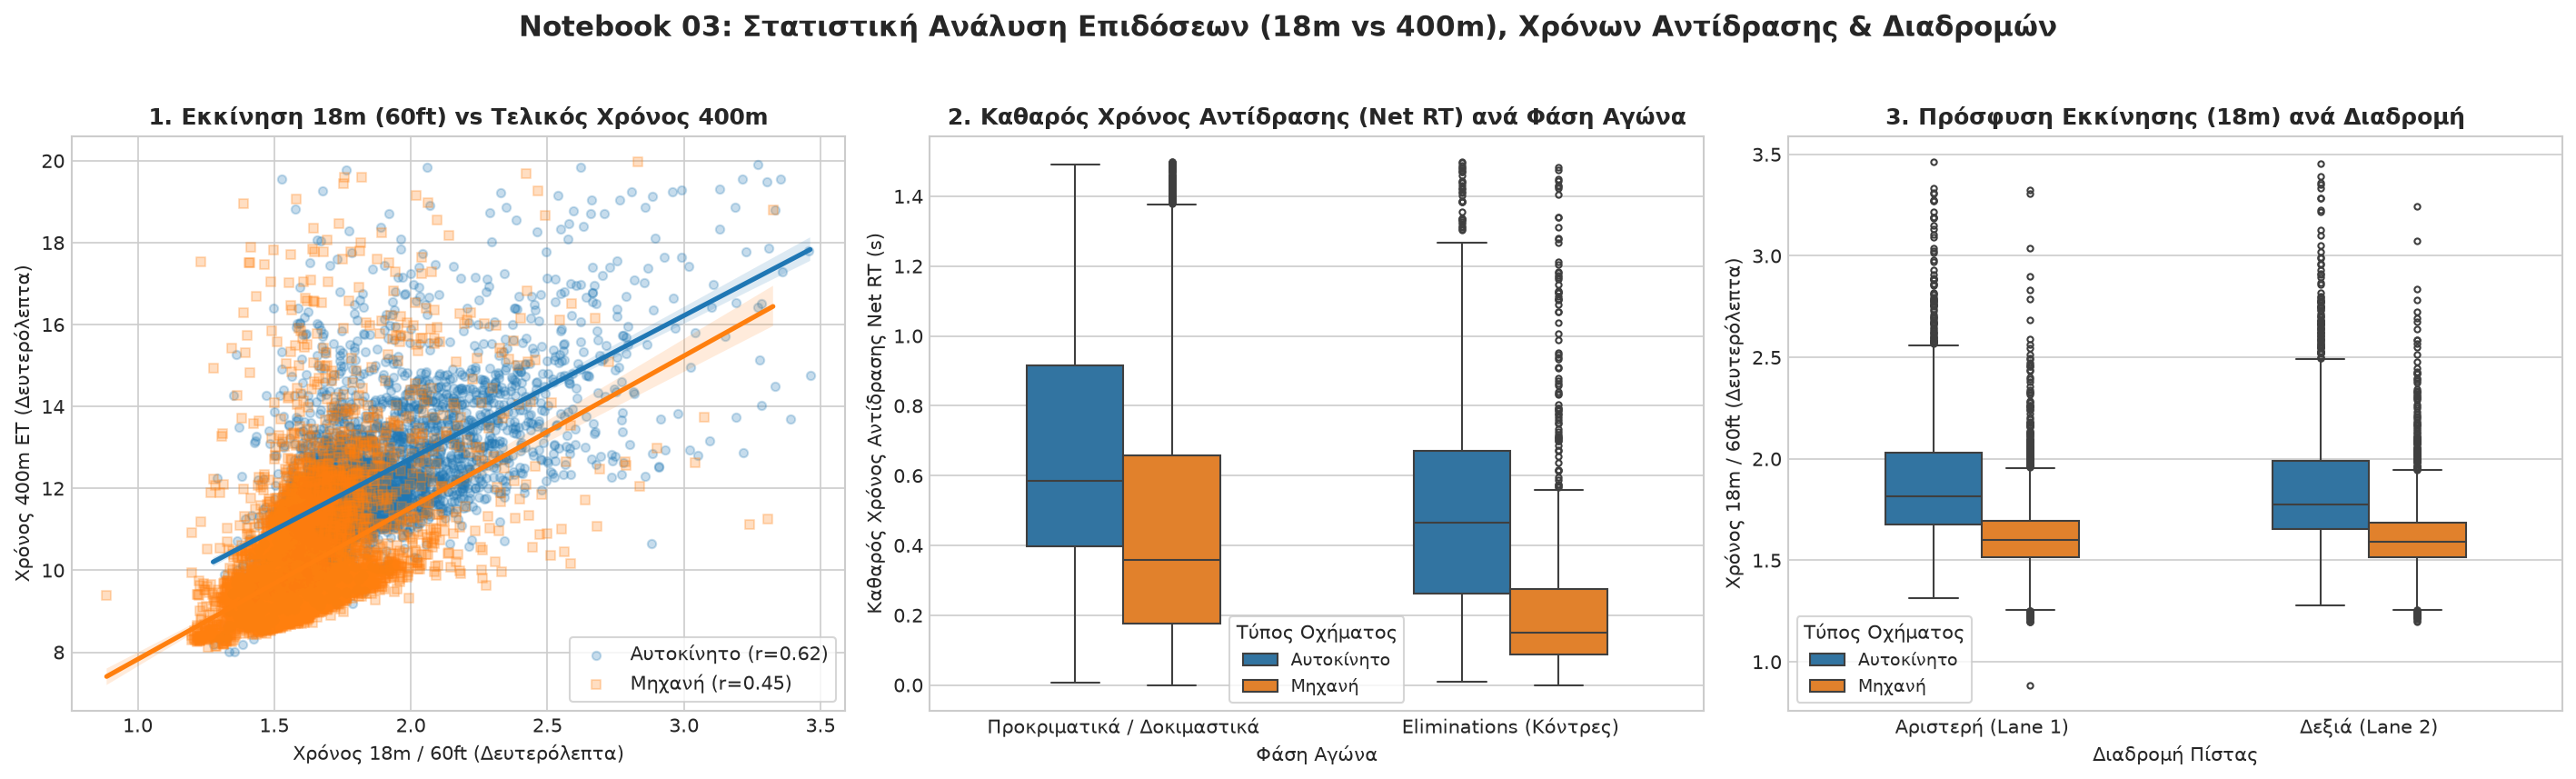

Το γράφημα αποθηκεύτηκε στο: ..\outputs\figures\03_performance_and_track_analysis.png


In [12]:
# Δημιουργία τριπλού γραφήματος ανάλυσης επιδόσεων και πίστας:
# (1) Scatter & Γραμμική Παλινδρόμηση Χρόνου 18m (60ft) vs Χρόνου 400m ET,
# (2) Boxplot Καθαρού Χρόνου Αντίδρασης (Net RT) σε Προκριματικά vs Eliminations,
# (3) Boxplot Πρόσφυσης Εκκίνησης (18m) σε Αριστερή vs Δεξιά Διαδρομή.

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), dpi=150)
fig.suptitle('Notebook 03: Στατιστική Ανάλυση Επιδόσεων (18m vs 400m), Χρόνων Αντίδρασης & Διαδρομών', fontsize=15, fontweight='bold', y=1.03)

# 1. Scatter & Regression Plot: 18m (60ft) vs 400m ET
ax1 = axes[0]
for vtype, color, marker in [('Αυτοκίνητο', '#1f77b4', 'o'), ('Μηχανή', '#ff7f0e', 's')]:
    sub = clean_400[clean_400['ΤύποςΟχήματος'] == vtype]
    sns.regplot(
        data=sub, x='Χρόνος18_sec', y='Χρόνος400_sec', ax=ax1, color=color,
        marker=marker, scatter_kws={'alpha': 0.25, 's': 20}, line_kws={'linewidth': 2.5},
        label=f'{vtype} (r={sub["Χρόνος18_sec"].corr(sub["Χρόνος400_sec"]):.2f})'
    )
ax1.set_title('1. Εκκίνηση 18m (60ft) vs Τελικός Χρόνος 400m', fontsize=12, fontweight='bold')
ax1.set_xlabel('Χρόνος 18m / 60ft (Δευτερόλεπτα)')
ax1.set_ylabel('Χρόνος 400m ET (Δευτερόλεπτα)')
ax1.legend(frameon=True, fontsize=10)

# 2. Boxplot: Καθαρός Χρόνος Αντίδρασης (Net RT) ανά Φάση Αγώνα & Όχημα
ax2 = axes[1]
sns.boxplot(
    data=rt_clean, x='Φάση_Αγώνα', y='Net_RT_sec', hue='ΤύποςΟχήματος',
    order=['Προκριματικά / Δοκιμαστικά', 'Eliminations (Κόντρες)'],
    palette=['#1f77b4', '#ff7f0e'], width=0.5, fliersize=3, ax=ax2
)
ax2.set_title('2. Καθαρός Χρόνος Αντίδρασης (Net RT) ανά Φάση Αγώνα', fontsize=12, fontweight='bold')
ax2.set_xlabel('Φάση Αγώνα')
ax2.set_ylabel('Καθαρός Χρόνος Αντίδρασης Net RT (s)')
ax2.legend(title='Τύπος Οχήματος', frameon=True, fontsize=9)

# 3. Boxplot: Πρόσφυση Εκκίνησης (18m) ανά Διαδρομή (Αριστερή vs Δεξιά)
ax3 = axes[2]
sns.boxplot(
    data=clean_400, x='Διαδρομή_Όνομα', y='Χρόνος18_sec', hue='ΤύποςΟχήματος',
    order=['Αριστερή (Lane 1)', 'Δεξιά (Lane 2)'],
    palette=['#1f77b4', '#ff7f0e'], width=0.5, fliersize=3, ax=ax3
)
ax3.set_title('3. Πρόσφυση Εκκίνησης (18m) ανά Διαδρομή', fontsize=12, fontweight='bold')
ax3.set_xlabel('Διαδρομή Πίστας')
ax3.set_ylabel('Χρόνος 18m / 60ft (Δευτερόλεπτα)')
ax3.legend(title='Τύπος Οχήματος', frameon=True, fontsize=9)

plt.tight_layout()
out_fig = os.path.join(FIGURES_DIR, "03_performance_and_track_analysis.png")
plt.savefig(out_fig, dpi=150, bbox_inches='tight')
plt.show()
print(f"Το γράφημα αποθηκεύτηκε στο: {out_fig}")